# Analyse des données logistiques

Une IA générative (Claude) a été utilisée pour relire et corriger le nettoyage, restructurer et simplifier le code de l’analyse.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Graphes (cours 4)
import networkx as nx
# Détection d'anomalies et clustering (cours 2 et 3)
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.cluster import DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
# Règles d'association (cours 3)
from mlxtend.frequent_patterns import apriori, association_rules

import warnings
warnings.filterwarnings("ignore", message="vert: bool")

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

dossier = "../data/logistics/clean/"
commandes = pd.read_csv(dossier + "purchase_order_lines_clean.csv", parse_dates=["order_date", "requested_delivery_date"])
receptions = pd.read_csv(dossier + "goods_receipts_clean.csv", parse_dates=["receipt_date"])
stocks = pd.read_csv(dossier + "inventory_month_end_clean.csv", parse_dates=["reporting_month"])
ajustements = pd.read_csv(dossier + "inventory_adjustments_clean.csv", parse_dates=["adjustment_date"])
expeditions = pd.read_csv(dossier + "shipments_clean.csv", parse_dates=["dispatch_time", "arrival_time"])
# Sites et partenaires indexés par leur code, pour retrouver facilement leurs infos
sites = pd.read_csv(dossier + "erp_facilities_clean.csv", index_col="facility_code")
partenaires = pd.read_csv(dossier + "erp_business_partners_clean.csv", index_col="partner_code")

`regle_vers_cible` calcule le **support, la confiance et le lift**. Un lift calculé sur très peu de lignes n'est pas fiable : on fixe donc un seuil de support (au moins 8 lignes par modalité).

In [2]:
def regle_vers_cible(df, colonne, cible, min_n=8):
    # Nombre total de lignes et nombre de lignes où la cible est vraie
    total = len(df)
    total_cible = df[cible].sum()

    # Pour chaque modalité : n = nombre de lignes, k = nombre de lignes avec la cible
    res = df.groupby(colonne)[cible].agg(n="size", k="sum")
    # Support : part des lignes qui ont à la fois X et la cible
    res["support"] = res["k"] / total
    # Confiance : parmi les lignes avec X, part qui a la cible
    res["confiance"] = res["k"] / res["n"]
    # Lift : confiance divisée par le taux global (> 1 = plus fréquent que la moyenne)
    res["lift"] = res["confiance"] / (total_cible / total)

    # Seuil de support : on ignore les modalités trop rares (moins de min_n lignes)
    res = res[res["n"] >= min_n]
    # Tri du plus grand lift au plus petit
    return res.sort_values("lift", ascending=False)

## 1. Commandes et réceptions

Jointure à gauche pour garder les commandes jamais reçues, puis contrôles de cohérence.

In [3]:
lignes = commandes.merge(receptions, on=["purchase_order_number", "purchase_order_line"],
                         how="left", suffixes=("", "_rec"), indicator=True)

# Commandes sans réception : on regarde leur statut
jamais_recues = lignes[lignes["_merge"] == "left_only"]
print("Statut des commandes jamais reçues :", jamais_recues["order_status"].value_counts().to_dict())

# Commandes reçues : on vérifie que commande et réception concordent
r = lignes[lignes["_merge"] == "both"].copy()
print("fournisseur différent :", (r["supplier_partner_code"] != r["supplier_partner_code_rec"]).sum())
print("site différent :", (r["ordering_facility_code"] != r["receiving_facility_code"]).sum())
print("unité différente :", (r["ordered_unit"] != r["received_unit"]).sum())
print("reçu > commandé :", (r["received_quantity"] > r["ordered_quantity"]).sum())

Statut des commandes jamais reçues : {'delayed': 18, 'pending': 14, 'cancelled': 8}
fournisseur différent : 0
site différent : 0
unité différente : 0
reçu > commandé : 0


Les 40 commandes sans réception sont en retard, en attente ou annulées, et les 610 autres concordent avec leur réception : rien de suspect.

Trois indicateurs : **taux de manque**, **retard** (par rapport à la date demandée) et **prix relatif** (prix / prix médian du même article, car il y a 5 devises). On les décrit avec statistiques, histogrammes et boxplots (cours 1).

Lignes avec manque : 65 / 610 (10.7%)


,taux_manque,retard,prix_relatif
count,610.00,610.00,610.00
mean,0.01,1.97,1.00
std,0.04,3.29,0.08
min,0.00,-22.00,0.83
25%,0.00,-1.00,0.94
50%,0.00,2.00,1.00
75%,0.00,5.00,1.06
max,0.22,7.00,1.19


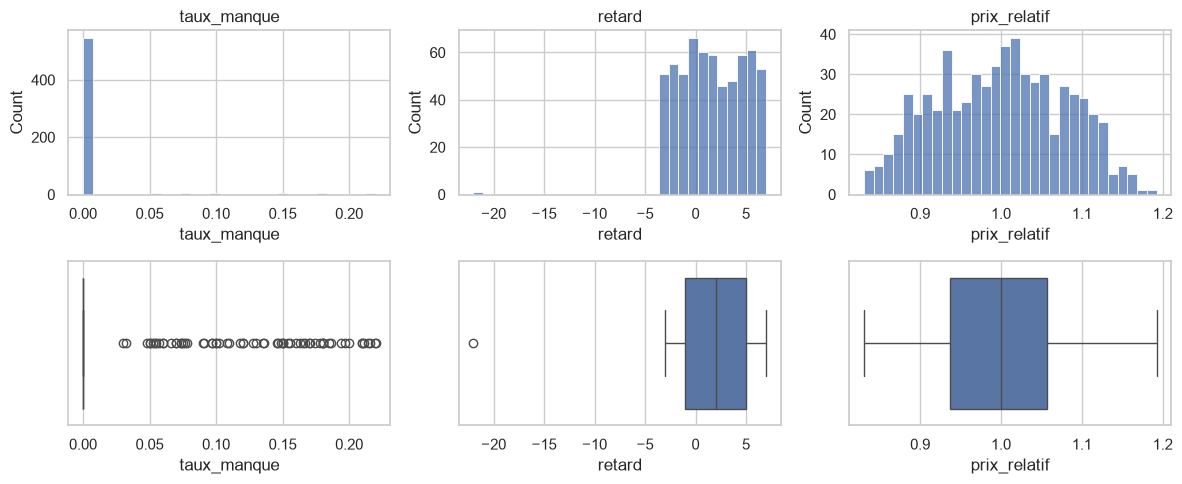

In [4]:
# Taux de manque : part de la quantité commandée qui n'a pas été reçue
r["taux_manque"] = (r["ordered_quantity"] - r["received_quantity"]) / r["ordered_quantity"]
# Vrai si la ligne a un manque
r["a_manque"] = r["taux_manque"] > 0
# Retard en jours par rapport à la date de livraison demandée
r["retard"] = (r["receipt_date"] - r["requested_delivery_date"]).dt.days

# Prix relatif : prix divisé par le prix médian du même article
prix_median_article = r.groupby("item_code")["unit_price"].transform("median")
r["prix_relatif"] = r["unit_price"] / prix_median_article

# Statistiques descriptives des 3 indicateurs
print(f"Lignes avec manque : {r['a_manque'].sum()} / {len(r)} ({r['a_manque'].mean():.1%})")
indicateurs = ["taux_manque", "retard", "prix_relatif"]
display(r[indicateurs].describe().round(2))

# Histogramme (ligne du haut) et boxplot (ligne du bas) pour chaque indicateur
fig, axes = plt.subplots(2, 3, figsize=(12, 5))
for j in range(3):
    col = indicateurs[j]
    sns.histplot(r[col], bins=30, ax=axes[0, j])
    sns.boxplot(x=r[col], ax=axes[1, j])
    axes[0, j].set_title(col)
plt.tight_layout()
plt.show()

- **Taux de manque :** nul pour 9 lignes sur 10, sinon entre 3 % et 22 %.
- **Retard :** faible, de −22 à +7 jours.
- **Prix relatif :** entre 0,83 et 1,19, donc aucun prix anormal.

Corrélations de Pearson (relations linéaires) et de Spearman (relations monotones), cours 1 :

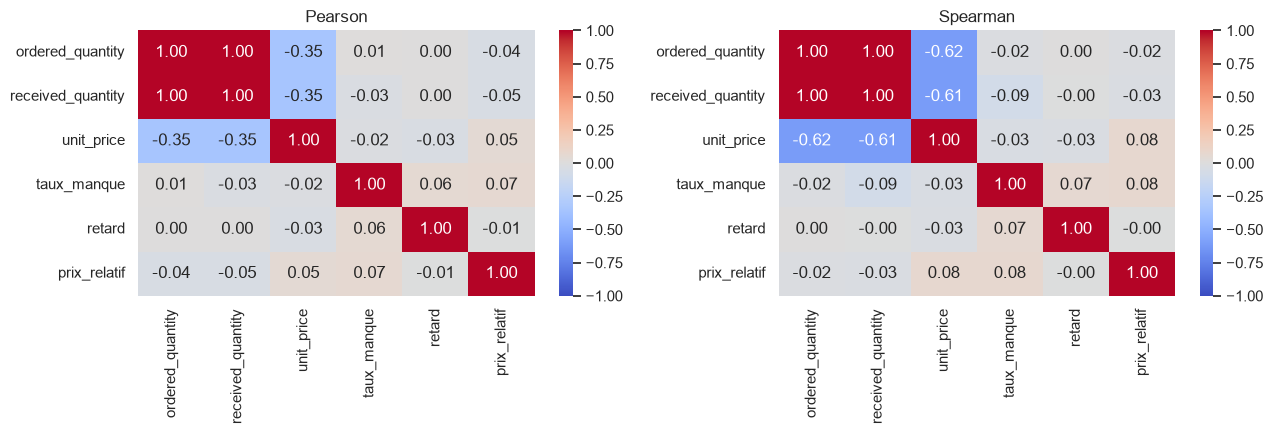

In [5]:
# Variables numériques à comparer
variables = ["ordered_quantity", "received_quantity", "unit_price", "taux_manque", "retard", "prix_relatif"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# Matrice de corrélation de Pearson (relations linéaires)
sns.heatmap(r[variables].corr("pearson"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson")
# Matrice de corrélation de Spearman (relations monotones, basée sur les rangs)
sns.heatmap(r[variables].corr("spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman")
plt.tight_layout()
plt.show()

Seules les corrélations attendues ressortent (quantité commandée et reçue, quantité et prix). Le manque et le retard ne sont liés à rien.

### Détection d'anomalies

DBSCAN et Isolation Forest sur les 4 indicateurs. Le taux de manque, déjà entre 0 et 1, n'est pas modifié ; les autres sont normalisés en min-max. `eps` est lu au coude de la courbe des k-distances.

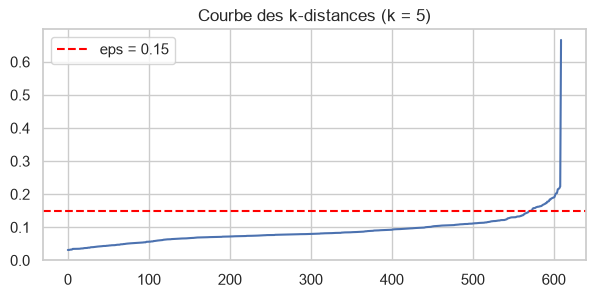

nombre  part_avec_manque
dbscan iforest                          
False  False       577              0.06
       True         18              1.00
True   False         2              0.50
       True         13              1.00

In [6]:
# Normalisation min-max : ramène une colonne entre 0 et 1
def min_max(colonne):
    return (colonne - colonne.min()) / (colonne.max() - colonne.min())

# Tableau des 4 variables utilisées pour la détection d'anomalies
X = pd.DataFrame()
# Le taux de manque est déjà entre 0 et 1 : on le garde tel quel
X["taux_manque"] = r["taux_manque"]
X["retard"] = min_max(r["retard"])
X["prix_relatif"] = min_max(r["prix_relatif"])
# log1p pour réduire l'effet des très grosses quantités
X["log_quantite"] = min_max(np.log1p(r["ordered_quantity"]))

# Courbe des k-distances : distance de chaque point à son 5e voisin, triée
voisins = NearestNeighbors(n_neighbors=5).fit(X)
distances, _ = voisins.kneighbors(X)
k_distances = np.sort(distances[:, -1])

# On trace la courbe et la valeur d'eps choisie au niveau du coude
plt.figure(figsize=(7, 3))
plt.plot(k_distances)
plt.axhline(0.15, color="red", ls="--", label="eps = 0.15")
plt.title("Courbe des k-distances (k = 5)")
plt.legend()
plt.show()

# DBSCAN et Isolation Forest renvoient -1 pour les anomalies
r["dbscan"] = DBSCAN(eps=0.15, min_samples=5).fit_predict(X) == -1
r["iforest"] = IsolationForest(contamination=0.05, random_state=42).fit_predict(X) == -1
# Pour chaque combinaison des deux méthodes : nombre de lignes et part avec un manque
display(r.groupby(["dbscan", "iforest"])["a_manque"].agg(nombre="size", part_avec_manque="mean").round(2))

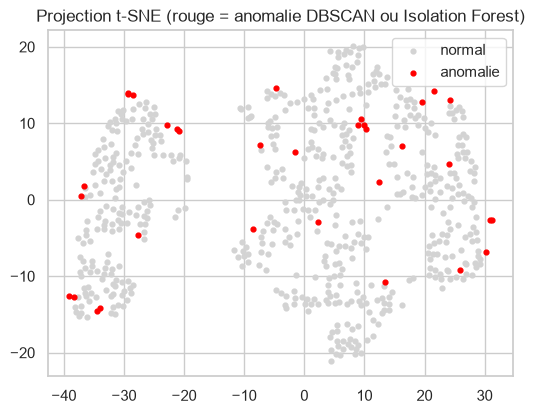

In [7]:
# Projection t-SNE des 4 variables en 2 dimensions pour visualiser les anomalies
tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)
# Vrai si la ligne est une anomalie pour au moins une des deux méthodes
anomalie = r["dbscan"] | r["iforest"]

# Points normaux en gris, anomalies en rouge
plt.figure(figsize=(6, 4.5))
plt.scatter(tsne[~anomalie, 0], tsne[~anomalie, 1], s=12, c="lightgrey", label="normal")
plt.scatter(tsne[anomalie, 0], tsne[anomalie, 1], s=12, c="red", label="anomalie")
plt.title("Projection t-SNE (rouge = anomalie DBSCAN ou Isolation Forest)")
plt.legend()
plt.show()

Les anomalies sont presque toutes des lignes avec un manque, dispersées sur le t-SNE : elles ne forment pas un groupe. Question suivante : **les manques sont-ils concentrés chez certains fournisseurs ou sites ?**

In [8]:
# Règles « X ⇒ manque » par fournisseur, par site et par catégorie (les 3 plus gros lifts de chaque)
for col in ["supplier_partner_code", "ordering_facility_code", "item_category"]:
    print(regle_vers_cible(r, col, "a_manque").head(3).round(3))
    print()

                        n  k  support  confiance   lift
supplier_partner_code                                  
BP-30079               10  3    0.005      0.300  2.815
BP-30033               11  3    0.005      0.273  2.559
BP-30037                8  2    0.003      0.250  2.346

                         n  k  support  confiance   lift
ordering_facility_code                                  
FCL-1014                15  4    0.007      0.267  2.503
FCL-1001                 8  2    0.003      0.250  2.346
FCL-1002                11  2    0.003      0.182  1.706

                        n  k  support  confiance   lift
item_category                                          
transport_service      30  6    0.010      0.200  1.877
communication_service  17  3    0.005      0.176  1.656
protective_equipment   47  7    0.011      0.149  1.398



**Conclusion :** les plus gros lifts (2,3 à 2,8 pour les fournisseurs et les sites) reposent sur 2 à 4 manques seulement, trop peu pour parler de concentration ; par catégorie, les lifts restent sous 1,9.

## 2. Bilans de stock

Équation attendue : **clôture = ouverture + reçu − sorti − usage interne − déchets**. L'`ecart` est la différence entre la clôture déclarée et la clôture attendue ; négatif = stock disparu.

In [9]:
# Tri par site, catégorie et mois pour avoir les bilans dans l'ordre
s = stocks.sort_values(["facility_code", "item_category", "reporting_month"]).copy()

# Clôture attendue d'après l'équation du stock
cloture_attendue = (s["opening_stock"] + s["received_quantity"] - s["outgoing_quantity"]
                    - s["documented_internal_use"] - s["documented_waste"])
# Écart = clôture déclarée - clôture attendue (négatif = stock disparu)
s["ecart"] = (s["closing_stock"] - cloture_attendue).round(2)

# La clôture d'un mois doit être égale à l'ouverture du mois suivant
ouverture_suivante = s.groupby(["facility_code", "item_category"])["opening_stock"].shift(-1)
ruptures = (ouverture_suivante - s["closing_stock"]).abs() > 0.005
print("Ruptures entre deux bilans :", ruptures.sum())
# Nombre de bilans dont l'écart est nul (à l'arrondi près)
print("Bilans qui respectent l'équation :", (s["ecart"].abs() < 0.01).sum(), "/", len(s))
# Écart moyen selon le statut du bilan
s.groupby("inventory_status")["ecart"].agg(["size", "mean"]).round(2)

Ruptures entre deux bilans : 0
Bilans qui respectent l'équation : 3 / 500


,size,mean
inventory_status,,
closed,444,0.37
provisional,38,-0.36
revised,18,-9.01


Les bilans s'enchaînent bien d'un mois à l'autre, mais l'équation n'est presque jamais respectée. Les bilans `revised` ont un écart moyen de −9 : repérés, mais pas corrigés.

### Écarts anormaux

On utilise l'**écart relatif** (écart / stock disponible) pour comparer des stocks de tailles différentes, avec deux règles : **IQR** et **z-score modifié** (seuil −3,5).

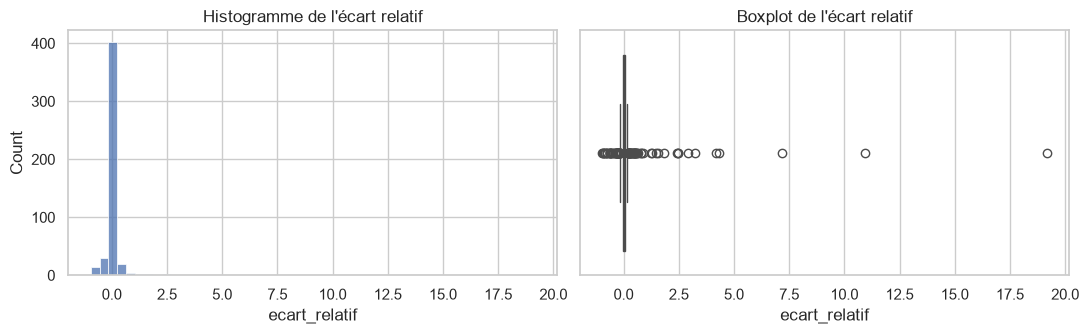

Seuil IQR : -0.16 -> 40 bilans signalés
z-score modifié < -3,5 : 35 bilans


facility_code  item_category       
FCL-1027       biological_sample       8
FCL-1020       biological_sample       7
FCL-1019       biological_sample       7
FCL-1024       biological_sample       6
               protective_equipment    2
dtype: int64

In [10]:
# Stock disponible dans le mois = ouverture + reçu
s["stock_dispo"] = s["opening_stock"] + s["received_quantity"]
# Pas de stock disponible : on met NaN pour ne pas diviser par 0
s.loc[s["stock_dispo"] <= 0, "stock_dispo"] = np.nan
# Écart relatif = écart rapporté au stock disponible
s["ecart_relatif"] = s["ecart"] / s["stock_dispo"]

# Histogramme et boxplot de l'écart relatif
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(s["ecart_relatif"].dropna(), bins=50, ax=axes[0])
sns.boxplot(x=s["ecart_relatif"], ax=axes[1])
axes[0].set_title("Histogramme de l'écart relatif")
axes[1].set_title("Boxplot de l'écart relatif")
plt.tight_layout()
plt.show()

# Règle IQR : anormal si la valeur est sous Q1 - 1,5 x (Q3 - Q1)
q1 = s["ecart_relatif"].quantile(0.25)
q3 = s["ecart_relatif"].quantile(0.75)
seuil_iqr = q1 - 1.5 * (q3 - q1)
s["iqr"] = s["ecart_relatif"] < seuil_iqr

# z-score modifié : comme un z-score, mais avec la médiane et le MAD (moins sensibles aux extrêmes)
mediane = s["ecart_relatif"].median()
mad = (s["ecart_relatif"] - mediane).abs().median()
s["z_modifie"] = 0.6745 * (s["ecart_relatif"] - mediane) / mad

print(f"Seuil IQR : {seuil_iqr:.2f} -> {s['iqr'].sum()} bilans signalés")
print(f"z-score modifié < -3,5 : {(s['z_modifie'] < -3.5).sum()} bilans")
# Les couples site + catégorie qui ont le plus de bilans signalés par la règle IQR
s[s["iqr"]].groupby(["facility_code", "item_category"]).size().sort_values(ascending=False).head(5)

Les bilans signalés concernent **surtout les échantillons biologiques**, à FCL-1027, FCL-1020, FCL-1019 et FCL-1024. On regarde aussi les pertes en valeur absolue :

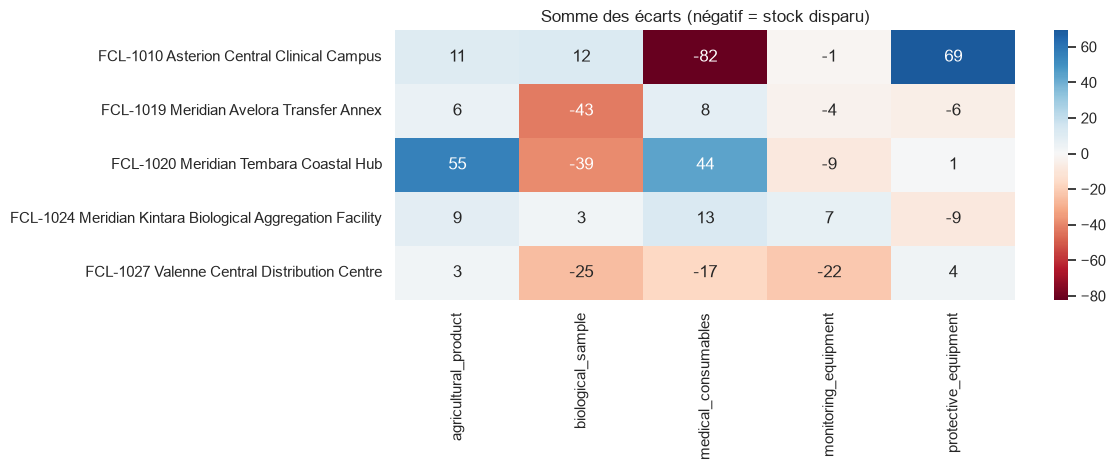

,,somme_ecarts,stock_moyen,bilans_signales
facility_code,item_category,,,
FCL-1010,medical_consumables,-82.2,159.8,1
FCL-1019,biological_sample,-42.6,16.8,7
FCL-1020,biological_sample,-38.7,7.0,7
FCL-1027,biological_sample,-25.2,7.1,8


In [11]:
# Nom lisible du site (code + nom) pour la carte
s["site"] = s["facility_code"] + " " + s["facility_code"].map(sites["facility_name"])
# Somme des écarts pour chaque site (lignes) et chaque catégorie (colonnes)
somme_ecarts = s.pivot_table(index="site", columns="item_category", values="ecart", aggfunc="sum")

# Carte de chaleur : rouge = stock disparu, bleu = stock en trop
plt.figure(figsize=(10, 3.5))
sns.heatmap(somme_ecarts, annot=True, fmt=".0f", cmap="RdBu", center=0)
plt.title("Somme des écarts (négatif = stock disparu)")
plt.xlabel("")
plt.ylabel("")
plt.show()

# Pour chaque couple site + catégorie : perte totale, stock moyen et nombre de bilans signalés
par_couple = s.groupby(["facility_code", "item_category"]).agg(somme_ecarts=("ecart", "sum"),
                                                              stock_moyen=("opening_stock", "mean"),
                                                              bilans_signales=("iqr", "sum"))
# Les 4 couples qui perdent le plus
par_couple.sort_values("somme_ecarts").head(4).round(1)

- **FCL-1010, consommables médicaux :** plus grosse perte (−82 caisses), mais modérée pour un stock moyen de 160.
- **FCL-1019 et FCL-1020, échantillons biologiques :** −43 et −39 lots, soit plusieurs fois leur stock moyen.

### Les mois de « transit pur »

Dans les bilans signalés de ces deux sites, certains mois la quantité reçue est **exactement égale** à la quantité sortie.

In [12]:
# Mois de transit : on a reçu quelque chose et tout est ressorti (reçu = sorti)
s["transit"] = (s["received_quantity"] > 0) & (s["received_quantity"] == s["outgoing_quantity"])
transit = s[s["transit"]]
display(transit[["facility_code", "item_category", "reporting_month", "opening_stock",
                 "received_quantity", "closing_stock", "ecart", "iqr"]])

# Écart moyen des mois de transit comparé aux autres mois
print("Écart moyen :", s.groupby("transit")["ecart"].mean().round(2).to_dict())
# Tableau croisé : mois de transit x signalé par la règle IQR
pd.crosstab(s["transit"], s["iqr"], rownames=["mois de transit"], colnames=["signalé par la règle IQR"], margins=True)

,facility_code,item_category,reporting_month,opening_stock,received_quantity,closing_stock,ecart,iqr
102,FCL-1019,biological_sample,2018-05-01,57.30,3.0,30.32,-17.63,True
106,FCL-1019,biological_sample,2019-11-01,28.43,7.0,3.38,-21.80,True
108,FCL-1019,biological_sample,2020-06-01,9.52,5.0,0.00,-8.83,True
110,FCL-1019,biological_sample,2021-05-01,5.53,2.0,0.00,-4.49,True
114,FCL-1019,biological_sample,2023-11-01,6.57,8.0,0.00,-5.72,True
116,FCL-1019,biological_sample,2024-05-01,0.00,3.0,0.00,0.31,False
119,FCL-1019,biological_sample,2025-06-01,2.72,8.0,0.00,-2.50,True
200,FCL-1020,biological_sample,2018-02-01,37.80,3.0,21.66,-12.30,True
204,FCL-1020,biological_sample,2019-08-01,6.37,2.0,0.00,-4.97,True
211,FCL-1020,biological_sample,2022-02-01,8.63,7.0,0.00,-8.15,True


Écart moyen : {False: 0.18, True: -8.95}


signalé par la règle IQR,False,True,All
mois de transit,,,
False,459,30,489
True,1,10,11
All,460,40,500


**11 mois de transit**, tous sur les échantillons de FCL-1019 et FCL-1020. Écart moyen de −9 (contre +0,2 ailleurs) et clôture à 0 dans 8 cas : le lot entre, ressort, et le stock déjà là disparaît. **La règle IQR en signale 10 sur 11** (contre 30 sur 489 pour les autres mois) ; le seul raté avait un stock déjà vide.

### Comparaison avec les méthodes multivariées

Isolation Forest et LOF sur les ratios du bilan, sans standardisation car ce sont des ratios et un indicateur binaire.

In [13]:
# Variables du bilan rapportées au stock disponible (ratios) + indicateur de clôture nulle
Xs = pd.DataFrame()
Xs["ecart"] = s["ecart_relatif"]
Xs["sortie"] = s["outgoing_quantity"] / s["stock_dispo"]
Xs["usage"] = (s["documented_internal_use"] + s["documented_waste"]) / s["stock_dispo"]
Xs["cloture_nulle"] = (s["closing_stock"] == 0).astype(int)
# Les bilans sans stock disponible donnent NaN : on les remplace par 0
Xs = Xs.fillna(0)

# Les 4 méthodes à comparer (Vrai = bilan signalé comme anormal)
methodes = {
    "IQR sur l'écart relatif (univarié)": s["iqr"],
    "z-score modifié (univarié)": s["z_modifie"] < -3.5,
    "Isolation Forest (multivarié)": IsolationForest(contamination=0.05, random_state=42).fit_predict(Xs) == -1,
    "LOF (multivarié)": LocalOutlierFactor(n_neighbors=20, contamination=0.05).fit_predict(Xs) == -1,
}

# Pour chaque méthode : nombre de bilans signalés et combien sont des mois de transit
comparaison = []
for nom, signale in methodes.items():
    comparaison.append({"méthode": nom,
                        "bilans signalés": signale.sum(),
                        "dont mois de transit (sur 11)": (signale & s["transit"]).sum()})
pd.DataFrame(comparaison)

,méthode,bilans signalés,dont mois de transit (sur 11)
0,IQR sur l'écart relatif (univarié),40,10
1,z-score modifié (univarié),35,10
2,Isolation Forest (multivarié),25,0
3,LOF (multivarié),25,1


Isolation Forest et LOF ratent les mois de transit : ils repèrent les valeurs extrêmes, alors que ces mois ont des valeurs normales une à une. C'est la règle métier (l'équation) qui les rend anormaux : une valeur aberrante n'est pas forcément une anomalie, et inversement.

## 3. Expéditions : le circuit des échantillons biologiques

In [14]:
# Renvoie la valeur la plus fréquente d'une colonne
def plus_frequent(colonne):
    return colonne.mode()[0]

# On ne garde que les expéditions d'échantillons biologiques
bio = expeditions[expeditions["item_category"] == "biological_sample"].copy()
# Itinéraire = site de départ → site d'arrivée
bio["itineraire"] = bio["origin_facility_code"] + " → " + bio["destination_facility_code"]

# Pour chaque itinéraire : nombre d'expéditions et acteurs les plus fréquents
itineraires = bio.groupby("itineraire").agg(n=("shipment_number", "size"),
                                            motif=("declared_purpose", plus_frequent),
                                            expediteur=("sender_partner_code", plus_frequent),
                                            destinataire=("receiver_partner_code", plus_frequent),
                                            transporteur=("carrier_partner_code", plus_frequent))
# Les 5 itinéraires les plus utilisés
itineraires.sort_values("n", ascending=False).head(5)

,n,motif,expediteur,destinataire,transporteur
itineraire,,,,,
FCL-1011 → FCL-1007,8,temperature-controlled clinical programme delivery,BP-30078,BP-30021,BP-30047
FCL-1019 → FCL-1019,7,environmental and wildlife reference materials,BP-30056,BP-30078,BP-30047
FCL-1030 → FCL-1024,7,environmental and wildlife reference materials,BP-30056,BP-30078,BP-30047
FCL-1011 → FCL-1010,7,temperature-controlled clinical programme delivery,BP-30078,BP-30021,BP-30047
FCL-1020 → FCL-1020,4,environmental and wildlife reference materials,BP-30056,BP-30078,BP-30047


In [15]:
# Informations sur les sites du circuit
display(sites.loc[["FCL-1030", "FCL-1024", "FCL-1019", "FCL-1020", "FCL-1011", "FCL-1007", "FCL-1010"],
                  ["facility_name", "facility_category", "storage_capabilities"]])
# Informations sur les partenaires du circuit (dont le niveau de risque)
partenaires.loc[["BP-30056", "BP-30078", "BP-30021", "BP-30047"], ["partner_name", "partner_role", "risk_class"]]

,facility_name,facility_category,storage_capabilities
facility_code,,,
FCL-1030,Kintara Cave Authority Field Depot,field_depot,ambient
FCL-1024,Meridian Kintara Biological Aggregation Facility,warehouse,ambient;secure_cage;2-8C;frozen
FCL-1019,Meridian Avelora Transfer Annex,transfer_hub,ambient;secure_cage;2-8C;frozen
FCL-1020,Meridian Tembara Coastal Hub,transfer_hub,ambient;secure_cage;2-8C;frozen
FCL-1011,Meridian Valenne Headquarters,office,ambient
FCL-1007,Asterion Avelora Executive Clinic,clinical_delivery_point,2-8C;controlled_access
FCL-1010,Asterion Central Clinical Campus,laboratory_delivery_point,2-8C;controlled_access


,partner_name,partner_role,risk_class
partner_code,,,
BP-30056,Horizon Field Research Cooperative,customer,standard
BP-30078,Meridian BioLogistics,carrier,standard
BP-30021,Asterion Clinical Institute,customer,review
BP-30047,Northstar Cold Chain Services,carrier,elevated


Trois itinéraires principaux, toujours avec le transporteur **Northstar (BP-30047), classé à risque « elevated »** :
1. **FCL-1030 → FCL-1024** : dépôt des grottes de Kintara → Meridian, motif « matériel faunique » ;
2. **FCL-1019 → FCL-1019 et FCL-1020 → FCL-1020** : des sites qui s'envoient des colis **à eux-mêmes** ;
3. **FCL-1011 → FCL-1007 et FCL-1010** : siège de Meridian (bureau sans frigo) → cliniques Asterion, motif « programme clinique ».

### Expéditions vers soi-même et mois de transit

In [16]:
# Expéditions dont le site de départ est aussi le site d'arrivée
vers_soi = bio[bio["origin_facility_code"] == bio["destination_facility_code"]].copy()
# Mois de l'expédition (1er jour du mois), pour le comparer au mois du bilan
vers_soi["mois"] = vers_soi["dispatch_time"].dt.to_period("M").dt.to_timestamp()

# On rapproche chaque expédition vers soi-même du mois de transit du même site et du même mois
rappro = vers_soi.merge(transit, left_on=["origin_facility_code", "mois"],
                        right_on=["facility_code", "reporting_month"])
display(rappro[["shipment_number", "origin_facility_code", "mois", "declared_quantity", "received_quantity", "ecart"]])
# Combien ont exactement la même quantité dans les deux tables
print("Même quantité :", (rappro["declared_quantity"] == rappro["received_quantity"]).sum(), "/", len(vers_soi))

,shipment_number,origin_facility_code,mois,declared_quantity,received_quantity,ecart
0,SHP-2018-00004,FCL-1020,2018-02-01,3,3.0,-12.30
1,SHP-2018-00032,FCL-1019,2018-05-01,3,3.0,-17.63
2,SHP-2019-00009,FCL-1020,2019-08-01,2,2.0,-4.97
3,SHP-2019-00041,FCL-1019,2019-11-01,7,7.0,-21.80
4,SHP-2020-00038,FCL-1019,2020-06-01,5,5.0,-8.83
5,SHP-2021-00028,FCL-1019,2021-05-01,2,2.0,-4.49
6,SHP-2022-00018,FCL-1020,2022-02-01,7,7.0,-8.15
7,SHP-2023-00071,FCL-1019,2023-11-01,8,8.0,-5.72
8,SHP-2024-00011,FCL-1019,2024-05-01,3,3.0,0.31
9,SHP-2024-00044,FCL-1020,2024-08-01,3,3.0,-12.36


Même quantité : 11 / 11


Les 11 expéditions vers soi-même correspondent aux 11 mois de transit (même site, même mois, même quantité) : **ce sont de fausses expéditions qui cachent la disparition**.

### Graphe des expéditions

Chaque site est un nœud, chaque itinéraire un lien pondéré par la quantité. Pour chaque site : forces entrante et sortante, solde (sortant − entrant) et betweenness.

In [17]:
# Quantité totale expédiée pour chaque couple (départ, arrivée)
liens = bio.groupby(["origin_facility_code", "destination_facility_code"])["declared_quantity"].sum().reset_index()

# Construction du graphe orienté : un lien par itinéraire, pondéré par la quantité
G = nx.DiGraph()
for _, lien in liens.iterrows():
    G.add_edge(lien["origin_facility_code"], lien["destination_facility_code"], weight=lien["declared_quantity"])

# Boucles = liens d'un site vers lui-même
boucles = [u for u, v in nx.selfloop_edges(G)]
print(f"{G.number_of_nodes()} nœuds, {G.number_of_edges()} liens, densité {nx.density(G):.3f}, boucles : {boucles}")

# Pour chaque site : quantité reçue, quantité envoyée et rôle de pont (betweenness)
noeuds = pd.DataFrame({"force_entrante": dict(G.in_degree(weight="weight")),
                       "force_sortante": dict(G.out_degree(weight="weight")),
                       "betweenness": nx.betweenness_centrality(G)})
# Solde : positif = le site envoie plus qu'il ne reçoit (source), négatif = puits
noeuds["solde"] = noeuds["force_sortante"] - noeuds["force_entrante"]
noeuds["site"] = noeuds.index.map(sites["facility_name"])
noeuds = noeuds.sort_values("solde", ascending=False).round(3)

print("Sites qui envoient le plus (sources) :")
display(noeuds.head(3))
print("Sites qui reçoivent le plus (puits) :")
display(noeuds.tail(2))

21 nœuds, 21 liens, densité 0.050, boucles : ['FCL-1019', 'FCL-1020']
Sites qui envoient le plus (sources) :


,force_entrante,force_sortante,betweenness,solde,site
FCL-1011,15,118,0.026,103,Meridian Valenne Headquarters
FCL-1030,15,33,0.005,18,Kintara Cave Authority Field Depot
FCL-1020,15,33,0.000,18,Meridian Tembara Coastal Hub


Sites qui reçoivent le plus (puits) :


,force_entrante,force_sortante,betweenness,solde,site
FCL-1010,65,18,0.016,-47,Asterion Central Clinical Campus
FCL-1007,55,0,0.000,-55,Asterion Avelora Executive Clinic


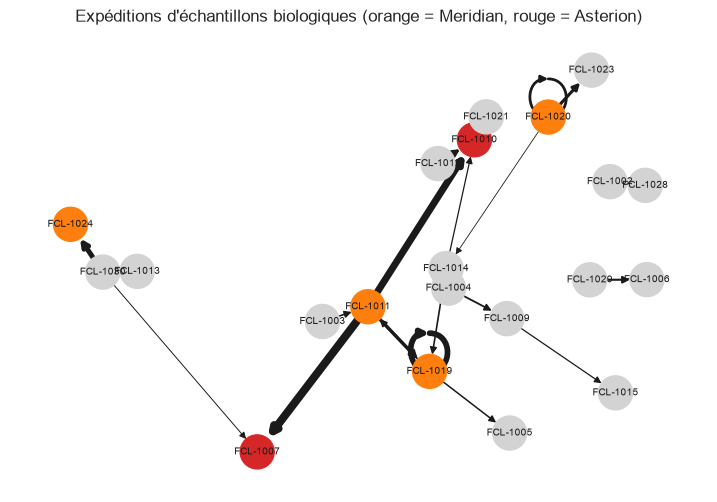

Louvain : 7 communautés, modularité 0.60
['FCL-1003', 'FCL-1007', 'FCL-1010', 'FCL-1011', 'FCL-1012', 'FCL-1021']
['FCL-1004', 'FCL-1009', 'FCL-1015']
['FCL-1005', 'FCL-1014', 'FCL-1019']
['FCL-1013', 'FCL-1024', 'FCL-1030']


In [18]:
# Couleur de chaque nœud selon l'entreprise qui exploite le site
couleurs = []
for site in G.nodes:
    operateur = sites.loc[site, "operating_partner_code"]
    if operateur == "BP-30078":
        couleurs.append("tab:orange")  # Meridian
    elif operateur == "BP-30021":
        couleurs.append("tab:red")     # Asterion
    else:
        couleurs.append("lightgrey")

# Épaisseur des flèches proportionnelle à la quantité expédiée
epaisseurs = [0.5 + G[u][v]["weight"] / 10 for u, v in G.edges]

# Dessin du graphe (seed fixée pour avoir toujours la même disposition)
plt.figure(figsize=(9, 6))
position = nx.spring_layout(G, seed=42, k=0.6)
nx.draw_networkx(G, position, node_color=couleurs, node_size=600, font_size=7, width=epaisseurs, arrows=True)
plt.title("Expéditions d'échantillons biologiques (orange = Meridian, rouge = Asterion)")
plt.axis("off")
plt.show()

# Louvain : détection de communautés sur le graphe non orienté, sans les boucles
U = G.to_undirected()
U.remove_edges_from(list(nx.selfloop_edges(U)))
communautes = nx.community.louvain_communities(U, weight="weight", seed=42)
# Modularité : qualité du découpage (proche de 1 = communautés bien séparées)
modularite = nx.community.modularity(U, communautes, weight="weight")
print(f"Louvain : {len(communautes)} communautés, modularité {modularite:.2f}")
# Affichage des 4 plus grandes communautés
for c in sorted(communautes, key=len, reverse=True)[:4]:
    print(sorted(c))

- **FCL-1011 (siège Meridian) est une source :** 118 lots envoyés pour 15 reçus.
- **FCL-1010 et FCL-1007 (cliniques Asterion) sont des puits.**
- **Les boucles** sur FCL-1019 et FCL-1020 sont les fausses expéditions.

Louvain sépare la partie Kintara (FCL-1030, FCL-1024) du groupe siège + cliniques. **FCL-1024 n'expédie rien** : aucun passage n’est enregistré entre ces deux groupes.

### Co-occurrences et règles d'association

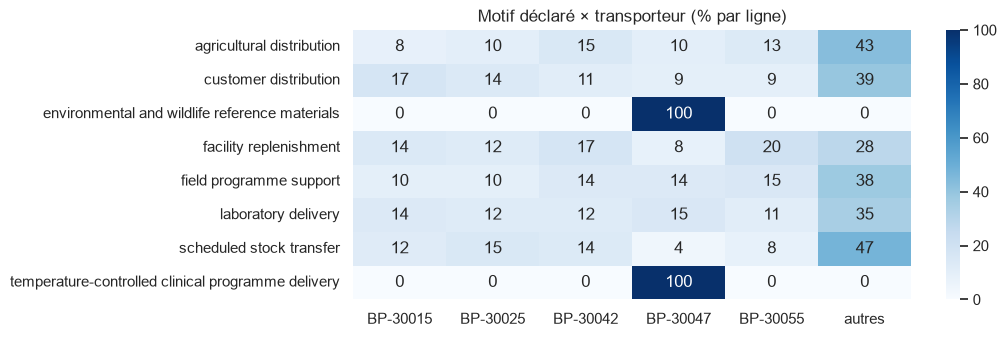

In [19]:
# On garde les 5 transporteurs les plus utilisés, les autres sont regroupés dans "autres"
top5 = expeditions["carrier_partner_code"].value_counts().index[:5]
transporteur = expeditions["carrier_partner_code"].copy()
transporteur[~transporteur.isin(top5)] = "autres"

# Matrice de co-occurrence motif x transporteur, en % de chaque ligne
cooccurrence = pd.crosstab(expeditions["declared_purpose"], transporteur, normalize="index") * 100

plt.figure(figsize=(9, 3.5))
sns.heatmap(cooccurrence, annot=True, fmt=".0f", cmap="Blues")
plt.title("Motif déclaré × transporteur (% par ligne)")
plt.xlabel("")
plt.ylabel("")
plt.show()

Les deux motifs passent **à 100 % par BP-30047**. Apriori sur toutes les expéditions (support ≥ 2 %, confiance ≥ 0,8, lift ≥ 3) :

In [20]:
# Colonnes décrivant une expédition
colonnes = ["item_category", "declared_purpose", "carrier_partner_code", "sender_partner_code",
            "receiver_partner_code", "origin_facility_code", "destination_facility_code"]
# Une colonne vrai/faux par valeur (format attendu par Apriori)
items = pd.get_dummies(expeditions[colonnes], prefix_sep="=").astype(bool)

# Itemsets fréquents (présents dans au moins 2 % des expéditions), puis règles avec lift >= 3
frequents = apriori(items, min_support=0.02, use_colnames=True, max_len=4)
regles = association_rules(frequents, metric="lift", min_threshold=3)

# On garde les règles sûres (confiance >= 0,8) qui partent d'un seul élément
regles = regles[(regles["confidence"] >= 0.8) & (regles["antecedents"].apply(len) == 1)].copy()
# Nombre d'expéditions concernées par la règle
regles["n"] = (regles["support"] * len(expeditions)).round().astype(int)
# Prémisse et conclusion en texte lisible
regles["si"] = regles["antecedents"].apply(lambda x: ", ".join(x))
regles["alors"] = regles["consequents"].apply(lambda x: ", ".join(sorted(x)))

# Pour chaque motif déclaré, on affiche la règle avec la conclusion la plus longue
motifs = regles[regles["si"].str.startswith("declared_purpose")]
plus_longue = motifs.groupby("si")["alors"].apply(lambda x: x.str.len().idxmax())
motifs.loc[plus_longue, ["si", "alors", "n", "confidence", "lift"]].round(2)

,si,alors,n,confidence,lift
560,declared_purpose=environmental and wildlife reference materials,"carrier_partner_code=BP-30047, item_category=biological_sample, receiver_partner_code=BP-30078",18,1.0,23.68
1137,declared_purpose=temperature-controlled clinical programme delivery,"carrier_partner_code=BP-30047, origin_facility_code=FCL-1011, receiver_partner_code=BP-30021",26,1.0,16.67


Sans hypothèse de départ, Apriori retrouve les deux circuits avec une **confiance de 1** (18 expéditions « faune », 26 « programme clinique »).

In [21]:
# Premier envoi « faune » et première livraison aux cliniques
exp = pd.read_csv("../data/logistics/clean/shipments_clean.csv", parse_dates=["dispatch_time"])
faune = exp[exp["declared_purpose"] == "environmental and wildlife reference materials"]
clinique = exp[exp["declared_purpose"] == "temperature-controlled clinical programme delivery"]
print("Premier envoi « faune » :", faune["dispatch_time"].min().date(), "| première livraison aux cliniques :", clinique["dispatch_time"].min().date())

Premier envoi « faune » : 2018-02-16 | première livraison aux cliniques : 2014-07-10


## 4. Ajustements de stock

Négatif = retrait de stock, positif = ajout.

In [22]:
# Vrai si l'ajustement retire du stock
ajustements["negatif"] = ajustements["adjustment_quantity"] < 0
# Pour chaque motif d'ajustement : nombre, quantité totale et part de retraits
motifs_ajust = ajustements.groupby("adjustment_reason").agg(nombre=("adjustment_quantity", "size"),
                                                            total=("adjustment_quantity", "sum"),
                                                            part_negatifs=("negatif", "mean"))
# Tri du motif qui retire le plus à celui qui ajoute le plus
motifs_ajust.sort_values("total").round(2)

,nombre,total,part_negatifs
adjustment_reason,,,
specialist programme issue,11,-23.65,1.00
transfer posting correction,24,-22.47,0.67
procedure stock issue,10,-22.41,1.00
controlled-area consumption,9,-16.84,1.00
cycle count reconciliation,5,-16.22,1.00
unit-of-measure review,12,-8.80,0.67
cycle count correction,23,-7.69,0.48
quality-hold release,21,-1.56,0.52
damaged packaging write-off,16,-1.19,0.44


In [23]:
# On sépare les deux cliniques Asterion des autres sites
ajustements["groupe"] = np.where(ajustements["facility_code"].isin(["FCL-1007", "FCL-1010"]),
                                 "cliniques Asterion", "autres sites")

# Sites où les ajustements sont approuvés par ce rôle particulier
role_special = ajustements["approved_by_role"] == "specialist programme administrator"
print("Sites où approuve le « specialist programme administrator » :",
      sorted(ajustements.loc[role_special, "facility_code"].unique()))
# Nombre d'ajustements par motif, dans les cliniques Asterion et ailleurs
# Combien des retraits propres à Asterion sont approuvés par ce rôle
motifs_asterion = ["controlled-area consumption", "procedure stock issue", "specialist programme issue"]
propres_asterion = ajustements["adjustment_reason"].isin(motifs_asterion)
print("Retraits propres à Asterion :", propres_asterion.sum(), "| approuvés par ce rôle :", (propres_asterion & role_special).sum())
pd.crosstab(ajustements["adjustment_reason"], ajustements["groupe"])

Sites où approuve le « specialist programme administrator » : ['FCL-1007', 'FCL-1010']
Retraits propres à Asterion : 30 | approuvés par ce rôle : 13


groupe,autres sites,cliniques Asterion
adjustment_reason,,
controlled-area consumption,0,9
cycle count correction,23,0
cycle count reconciliation,5,0
damaged packaging write-off,14,2
late receipt posting,6,3
procedure stock issue,0,10
quality-hold release,21,0
specialist programme issue,0,11
transfer posting correction,24,0


Trois motifs de retrait n'existent **que dans les cliniques Asterion** (30 retraits). 13 d'entre eux sont approuvés par un « specialist programme administrator », un rôle absent des autres sites.

### Ajustements liés aux expéditions « faune »

In [24]:
# Ajustements qui citent une expédition, joints avec les infos de cette expédition
lies = ajustements.dropna(subset=["related_shipment_number"])
lies = lies.merge(expeditions, left_on="related_shipment_number", right_on="shipment_number", suffixes=("", "_exp"))
# Nombre de jours entre l'expédition et l'ajustement
lies["jours"] = (lies["adjustment_date"] - lies["dispatch_time"]).dt.days

# Un lien est cohérent si : même catégorie, 0 à 31 jours après l'envoi, et site d'origine ou de destination
meme_categorie = lies["item_category"] == lies["item_category_exp"]
delai_ok = lies["jours"].between(0, 31)
meme_site = (lies["facility_code"] == lies["origin_facility_code"]) | (lies["facility_code"] == lies["destination_facility_code"])
coherents = lies[meme_categorie & delai_ok & meme_site]
display(coherents[["adjustment_number", "facility_code", "adjustment_quantity", "adjustment_reason", "declared_purpose", "jours"]])

# Combien d'expéditions « faune » sont suivies d'un retrait cohérent
faune = expeditions[expeditions["declared_purpose"] == "environmental and wildlife reference materials"]
suivie_retrait = faune["shipment_number"].isin(coherents["shipment_number"])
print(f"Expéditions « faune » suivies d'un retrait : {suivie_retrait.sum()} / {len(faune)}")
# Expéditions « faune » sans retrait
faune.loc[~suivie_retrait, ["shipment_number", "origin_facility_code", "dispatch_time"]]

,adjustment_number,facility_code,adjustment_quantity,adjustment_reason,declared_purpose,jours
4,ADJ-2018-00019,FCL-1020,-2.01,cycle count reconciliation,environmental and wildlife reference materials,11
5,ADJ-2018-00023,FCL-1024,-4.14,transfer posting correction,environmental and wildlife reference materials,7
6,ADJ-2018-00027,FCL-1019,-2.95,transfer posting correction,environmental and wildlife reference materials,5
7,ADJ-2019-00039,FCL-1020,-2.69,transfer posting correction,environmental and wildlife reference materials,21
11,ADJ-2019-00046,FCL-1024,-1.08,quality-hold release,environmental and wildlife reference materials,16
12,ADJ-2019-00052,FCL-1019,-4.81,transfer posting correction,environmental and wildlife reference materials,21
14,ADJ-2020-00061,FCL-1024,-3.84,cycle count reconciliation,environmental and wildlife reference materials,19
15,ADJ-2020-00065,FCL-1019,-3.59,cycle count reconciliation,environmental and wildlife reference materials,17
16,ADJ-2021-00071,FCL-1024,-3.39,cycle count reconciliation,environmental and wildlife reference materials,4
21,ADJ-2021-00078,FCL-1019,-1.25,quality-hold release,environmental and wildlife reference materials,9


Expéditions « faune » suivies d'un retrait : 17 / 18


,shipment_number,origin_facility_code,dispatch_time
379,SHP-2024-00011,FCL-1019,2024-05-31 09:00:00


Les 17 liens cohérents sont **tous des retraits** d'échantillons chez Meridian, 4 à 21 jours après une expédition « faune », avec un motif banal. La seule exception (SHP-2024-00011) est le mois où le stock était déjà vide : rien à cacher.

## Conclusion

Les commandes ne montrent rien de suspect : les manques ne sont concentrés chez aucun fournisseur ni site. Le problème se trouve dans les **échantillons biologiques** de Meridian :

1. **Ils disparaissent des stocks** de FCL-1019 et FCL-1020 les mois de « transit » (11 mois, environ 9 lots perdus à chaque fois).
2. **Ces disparitions sont cachées** par de fausses expéditions vers soi-même (11 sur 11), puis effacées dans les comptes par des retraits « de correction » (17 expéditions « faune » sur 18).
3. **Deux flux passent par Meridian**, toujours avec le transporteur à risque Northstar :
   - les envois « faune » arrivent dans les entrepôts Meridian (depuis le dépôt des grottes de Kintara, ou par les fausses expéditions vers soi-même) et y disparaissent ;
   - le siège de Meridian envoie aux cliniques Asterion des lots qu'il n'a pas reçus, et ils y sortent du stock avec des motifs qu'on ne voit nulle part ailleurs.

Rien ne relie les deux flux dans les données : presque aucun lot ne va des entrepôts au siège, et les livraisons aux cliniques commencent en 2014, quatre ans avant le premier envoi « faune ». La logistique ne dit pas ce que contiennent les lots ni à quoi ils servent : c'est aux autres domaines (écologie, santé, registres publics) de le confirmer.